### **Description**

Recipe showing how to extract a meridional section across Drake Passage using annual-mean outputs from the National Oceanography Centre Near-Present-Day global eORCA1 configuration of NEMO forced using JRA55-do atmospheric forcing from 1976-2024.

For more details on this model configuration and the available outputs, users can explore the Near-Present-Day documentation [here](https://noc-msm.github.io/NOC_Near_Present_Day/).

---
### **Background**
Drake Passage is located between Antarctica's South Shetland Islands and the southernmost tip of South America and has been used by many sustained observing programs to measure the strength of the Antarctic Circumpolar Current (ACC) (e.g., Meredith et al., 2011; Chidichimo et al., 2014; Donohue et al., 2016).

The total volume transport of the ACC is known to play an important role in shaping the global transports of heat, fresh water, and carbon. It is common for the total volume transport to be decomposed into baroclinic (geostrophic flow referenced to zero velocity at the sea floor) and barotropic transport components.

In observational studies, the barotropic transport is calculated by integrating the sea water velocity at the sea floor over the full water column depth. Meanwhile, in numerical modelling studies, barotropic flow is typically defined as the depth-average flow, such that baroclinic flow represents departures from the vertical average (e.g., Xu et al., 2020).

---

In [1]:
# -- Import required packages -- #
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import xarray as xr

from nemo_cookbook import NEMODataTree

### **Using Dask**

**Optional: Connect Client to Dask Local Cluster to run analysis in parallel.**

Note that, although using Dask is not strictly necessary for this simple example using eORCA1, if we wanted to generalise this recipe to eORCA025 or eORCA12 outputs, using Dask would be essential to avoid unnecessary slow calculations using only a single process.

In [ ]:
# -- Initialise Dask Local Cluster -- #
import dask
from dask.distributed import Client, LocalCluster

# Update temporary directory for Dask workers:
dask.config.set({'temporary_directory': '/dssgfs01/working/otooth/Diagnostics/nemo_cookbook/recipes/',
                 'local_directory': '/dssgfs01/working/otooth/Diagnostics/nemo_cookbook/recipes/'
                 })

# Create Local Cluster:
cluster = LocalCluster(n_workers=5, threads_per_worker=2, memory_limit='8GB')
client = Client(cluster)
client

### **Accessing NEMO Model Data**
**Let's begin by loading the grid variables for our eORCA1 NEMO model from the [JASMIN Object Store](https://help.jasmin.ac.uk/docs/short-term-project-storage/using-the-jasmin-object-store/)**. 

**Alternatively, you can replace the ``domain_filepath`` below with a file path to your domain_cfg.nc file and read this with xarray's ``open_dataset()`` function.**

In [2]:
# Define directory path to ancillary files:
domain_url = "https://noc-msm-o.s3-ext.jc.rl.ac.uk/npd-eorca1-jra55v1/domain_cfg"

# Open eORCA1 NEMO model domain_cfg:
ds_domain = xr.open_zarr(domain_url, consolidated=True, chunks={})

ds_domain

<xarray.Dataset> Size: 709MB
Dimensions:       (y: 331, x: 360, nav_lev: 75)
Coordinates:
  * y             (y) int64 3kB 0 1 2 3 4 5 6 7 ... 324 325 326 327 328 329 330
  * x             (x) int64 3kB 0 1 2 3 4 5 6 7 ... 353 354 355 356 357 358 359
  * nav_lev       (nav_lev) int64 600B 0 1 2 3 4 5 6 7 ... 68 69 70 71 72 73 74
Data variables: (12/50)
    atlmsk        (y, x) int8 119kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    bathy_metry   (y, x) float32 477kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    bottom_level  (y, x) int32 477kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    e1f           (y, x) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    e1t           (y, x) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    e1u           (y, x) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    ...            ...
    top_level     (y, x) int32 477kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    umask         (nav_lev, y, x) int8 9MB dask.array<chunksize=(75, 331, 360), meta=np.ndarray>
    umaskutil     (y, x) int8 119kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    vmask         (nav_lev, y, x) int8 9MB dask.array<chunksize=(75, 331, 360), meta=np.ndarray>
    vmaskutil     (y, x) int8 119kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    wmask         (nav_lev, y, x) int8 9MB dask.array<chunksize=(75, 331, 360), meta=np.ndarray>
Attributes:
    CfgName:    UNKNOWN
    CfgIndex:   -999
    Iperio:     1
    Jperio:     0
    NFold:      1
    NFtype:     F
    VertCoord:  zps
    IsfCav:     0
    file_name:  mesh_mask.nc
    TimeStamp:  01/03/2025 22:19:49 -0000

**Next, we need to open the conservative temperature and absolute salinity variables stored at T-points as a single dataset.**

In [3]:
# Define directory path to model output files:
gridT_url = "https://noc-msm-o.s3-ext.jc.rl.ac.uk/npd-eorca1-jra55v1/T1y"

# Construct NEMO model T-grid dataset, including conservative temperature (deg C) and absolute salinity (g/kg) variables:
ds_gridT = xr.open_zarr(gridT_url, consolidated=True, chunks={}).sel(time_counter=slice("2010-01", "2023-12"))

ds_gridT

<xarray.Dataset> Size: 11GB
Dimensions:                (time_counter: 14, y: 331, x: 360, deptht: 75,
                            axis_nbounds: 2)
Coordinates:
  * time_counter           (time_counter) datetime64[ns] 112B 2010-07-02T12:0...
    time_centered          (time_counter) datetime64[ns] 112B dask.array<chunksize=(1,), meta=np.ndarray>
    nav_lat                (y, x) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    nav_lon                (y, x) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
  * deptht                 (deptht) float32 300B 0.5058 1.556 ... 5.902e+03
Dimensions without coordinates: y, x, axis_nbounds
Data variables: (12/74)
    berg_latent_heat_flux  (time_counter, y, x) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    deptht_bounds          (deptht, axis_nbounds) float32 600B dask.array<chunksize=(25, 2), meta=np.ndarray>
    e3t                    (time_counter, deptht, y, x) float32 500MB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
    empmr                  (time_counter, y, x) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    evs                    (time_counter, y, x) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    ficeberg               (time_counter, y, x) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    ...                     ...
    ttrd_qns_li            (time_counter, y, x) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    vohfcisf               (time_counter, deptht, y, x) float32 500MB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
    vohflisf               (time_counter, deptht, y, x) float32 500MB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
    vowflisf               (time_counter, deptht, y, x) float32 500MB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
    zos                    (time_counter, y, x) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    zossq                  (time_counter, y, x) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
Attributes:
    name:         OUTPUT/eORCA1_1y_grid_T
    description:  ocean T grid variables
    title:        ocean T grid variables
    Conventions:  CF-1.6
    timeStamp:    2024-Dec-09 10:28:01 GMT
    uuid:         89824b34-5d44-4531-8344-fe1ce39fbb7b

**Next, we need to import the zonal velocities and vertical grid cell thicknesses stored at U-points, respectively.**

In [4]:
# Define directory path to model output files:
gridU_url = "https://noc-msm-o.s3-ext.jc.rl.ac.uk/npd-eorca1-jra55v1/U1y"

# Construct NEMO model U-grid dataset, including zonal velocities (m/s) and vertical grid cell thicknesses (m):
ds_gridU = xr.open_zarr(gridU_url, consolidated=True, chunks={}).sel(time_counter=slice("2010-01", "2023-12"))

ds_gridU

<xarray.Dataset> Size: 3GB
Dimensions:               (depthu: 75, axis_nbounds: 2, time_counter: 14,
                           y: 331, x: 360)
Coordinates:
  * depthu                (depthu) float32 300B 0.5058 1.556 ... 5.902e+03
  * time_counter          (time_counter) datetime64[ns] 112B 2010-07-02T12:00...
    time_centered         (time_counter) datetime64[ns] 112B dask.array<chunksize=(1,), meta=np.ndarray>
    nav_lat               (y, x) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    nav_lon               (y, x) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
Dimensions without coordinates: axis_nbounds, y, x
Data variables: (12/14)
    depthu_bounds         (depthu, axis_nbounds) float32 600B dask.array<chunksize=(25, 2), meta=np.ndarray>
    e3u                   (time_counter, depthu, y, x) float32 500MB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
    hfx                   (time_counter, y, x) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    hfx_adv               (time_counter, y, x) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    hfx_diff              (time_counter, y, x) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    sozosatr              (time_counter, y, x) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    ...                    ...
    time_counter_bounds   (time_counter, axis_nbounds) datetime64[ns] 224B dask.array<chunksize=(1, 2), meta=np.ndarray>
    u2o                   (time_counter, depthu, y, x) float32 500MB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
    umo                   (time_counter, depthu, y, x) float32 500MB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
    umo_vint              (time_counter, y, x) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    uo                    (time_counter, depthu, y, x) float32 500MB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
    uo_eiv                (time_counter, depthu, y, x) float32 500MB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
Attributes:
    name:         OUTPUT/eORCA1_1y_grid_U
    description:  ocean U grid variables
    title:        ocean U grid variables
    Conventions:  CF-1.6
    timeStamp:    2024-Dec-09 10:18:04 GMT
    uuid:         8156ec68-1106-4f56-9f8c-d8798e1bd32f

### **Creating a NEMODataTree**

**Next, let's create a NEMODataTree to store our domain and T & U-grid variables for the eORCA1 model.**

In [5]:
# Define dictionary of grid datasets defining eORCA1 parent model domain with no child/grand-child nests:
datasets = {"parent":
            {"domain": ds_domain,
             "gridT": ds_gridT,
             "gridU": ds_gridU,
             }
            }

# Initialise a new NEMODataTree whose parent domain is zonally periodic & north-folding on F-points:
nemo = NEMODataTree.from_datasets(datasets=datasets, iperio=True, nftype="F", read_mask=True)

nemo

<xarray.DataTree 'NEMO model'>
Group: /
│   Dimensions:               (time_counter: 14, axis_nbounds: 2)
│   Coordinates:
│     * time_counter          (time_counter) datetime64[ns] 112B 2010-07-02T12:00...
│       time_centered         (time_counter) datetime64[ns] 112B dask.array<chunksize=(1,), meta=np.ndarray>
│   Dimensions without coordinates: axis_nbounds
│   Data variables:
│       time_centered_bounds  (time_counter, axis_nbounds) datetime64[ns] 224B dask.array<chunksize=(1, 2), meta=np.ndarray>
│       time_counter_bounds   (time_counter, axis_nbounds) datetime64[ns] 224B dask.array<chunksize=(1, 2), meta=np.ndarray>
│   Attributes:
│       nftype:   F
│       iperio:   True
├── Group: /gridT
│       Dimensions:                (time_counter: 14, j: 331, i: 360, k: 75,
│                                   axis_nbounds: 2)
│       Coordinates:
│           time_centered          (time_counter) datetime64[ns] 112B dask.array<chunksize=(1,), meta=np.ndarray>
│         * j                      (j) int64 3kB 1 2 3 4 5 6 ... 326 327 328 329 330 331
│         * i                      (i) int64 3kB 1 2 3 4 5 6 ... 355 356 357 358 359 360
│           gphit                  (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│           glamt                  (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│         * k                      (k) int64 600B 1 2 3 4 5 6 7 ... 69 70 71 72 73 74 75
│         * deptht                 (k) float64 600B 0.5058 1.556 ... 5.698e+03 5.902e+03
│       Dimensions without coordinates: axis_nbounds
│       Data variables: (12/78)
│           berg_latent_heat_flux  (time_counter, j, i) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
│           deptht_bounds          (k, axis_nbounds) float32 600B dask.array<chunksize=(25, 2), meta=np.ndarray>
│           e3t                    (time_counter, k, j, i) float32 500MB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
│           empmr                  (time_counter, j, i) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
│           evs                    (time_counter, j, i) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
│           ficeberg               (time_counter, j, i) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
│           ...                     ...
│           zos                    (time_counter, j, i) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
│           zossq                  (time_counter, j, i) float32 7MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
│           tmask                  (k, j, i) int8 9MB dask.array<chunksize=(75, 331, 360), meta=np.ndarray>
│           tmaskutil              (j, i) int8 119kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│           e1t                    (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│           e2t                    (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│       Attributes:
│           name:         OUTPUT/eORCA1_1y_grid_T
│           description:  ocean T grid variables
│           title:        ocean T grid variables
│           Conventions:  CF-1.6
│           timeStamp:    2024-Dec-09 10:28:01 GMT
│           uuid:         89824b34-5d44-4531-8344-fe1ce39fbb7b
├── Group: /gridU
│       Dimensions:               (k: 75, axis_nbounds: 2, time_counter: 14, j: 331,
│                                  i: 360)
│       Coordinates:
│         * k                     (k) int64 600B 1 2 3 4 5 6 7 ... 69 70 71 72 73 74 75
│         * depthu                (k) float64 600B 0.5058 1.556 ... 5.698e+03 5.902e+03
│           time_centered         (time_counter) datetime64[ns] 112B dask.array<chunksize=(1,), meta=np.ndarray>
│         * j                     (j) int64 3kB 1 2 3 4 5 6 ... 326 327 328 329 330 331
│         * i                     (i) float64 3kB 1.5 2.5 3.5 4.5 ... 358.5 35

### **Extracting the Drake Passage array as a meridional hydrographic section**

**Next, let's extract an approximately meridional section at the longitude of the Drake Passage from our NEMODataTree.**

**The resulting hydrographic section will be defined on the NEMO model U-grid at the constant i-coordinate whose average longitude is closest to 67°W.**

**We need to provide the names of the meridional vector variables (e.g., `v_vars=["tauvo"]`) and any scalar variables (e.g., `scalar_vars=['thetao_con', 'so_abs']`) to be linearly interpolated onto the U-grid.**

In [6]:
# Extract the Drake Passage array from the NEMO model data:
ds_drake_passage = nemo.extract_meridional_section(lon=-67,
                                                   lat_min=-67,
                                                   lat_max=-55,
                                                   v_vars=None,
                                                   scalar_vars=['thetao_con', 'so_abs'],
                                                   dom='.'
                                                   )

ds_drake_passage

<xarray.Dataset> Size: 997kB
Dimensions:               (k: 75, axis_nbounds: 2, time_counter: 14, bdy: 26)
Coordinates:
  * k                     (k) int64 600B 1 2 3 4 5 6 7 ... 69 70 71 72 73 74 75
  * depthb                (k) float64 600B 0.5058 1.556 ... 5.698e+03 5.902e+03
  * time_counter          (time_counter) datetime64[ns] 112B 2010-07-02T12:00...
    time_centered         (time_counter) datetime64[ns] 112B dask.array<chunksize=(1,), meta=np.ndarray>
  * j                     (bdy) int64 208B 81 82 83 84 85 ... 103 104 105 106
    gphib                 (bdy) float64 208B dask.array<chunksize=(26,), meta=np.ndarray>
    glamb                 (bdy) float64 208B dask.array<chunksize=(26,), meta=np.ndarray>
    i                     float64 8B 220.5
Dimensions without coordinates: axis_nbounds, bdy
Data variables: (12/22)
    depthu_bounds         (k, axis_nbounds) float32 600B dask.array<chunksize=(25, 2), meta=np.ndarray>
    e3b                   (time_counter, k, bdy) float32 109kB dask.array<chunksize=(1, 25, 26), meta=np.ndarray>
    hfx                   (time_counter, bdy) float32 1kB dask.array<chunksize=(1, 26), meta=np.ndarray>
    hfx_adv               (time_counter, bdy) float32 1kB dask.array<chunksize=(1, 26), meta=np.ndarray>
    hfx_diff              (time_counter, bdy) float32 1kB dask.array<chunksize=(1, 26), meta=np.ndarray>
    sozosatr              (time_counter, bdy) float32 1kB dask.array<chunksize=(1, 26), meta=np.ndarray>
    ...                    ...
    e1b                   (bdy) float64 208B dask.array<chunksize=(26,), meta=np.ndarray>
    e2b                   (bdy) float64 208B dask.array<chunksize=(26,), meta=np.ndarray>
    thetao_con            (time_counter, k, bdy) float64 218kB dask.array<chunksize=(1, 25, 26), meta=np.ndarray>
    so_abs                (time_counter, k, bdy) float64 218kB dask.array<chunksize=(1, 25, 26), meta=np.ndarray>
    i_bdy                 (bdy) float64 208B 220.5 220.5 220.5 ... 220.5 220.5
    j_bdy                 (bdy) int64 208B 81 82 83 84 85 ... 103 104 105 106
Attributes:
    name:         OUTPUT/eORCA1_1y_grid_U
    description:  ocean U grid variables
    title:        ocean U grid variables
    Conventions:  CF-1.6
    timeStamp:    2024-Dec-09 10:18:04 GMT
    uuid:         8156ec68-1106-4f56-9f8c-d8798e1bd32f

**Taking a closer look at our hydrographic section dataset, we can see it is structured analogously to a NEMO model grid node within our `NEMODataTree`:**

* Inherited NEMO Grid Dimension: `k`

* New Along-Boundary Grid Dimension: `bdy`, such that `i_bdy(bdy)`, `j_bdy(bdy)`

* Geographical Coordinates: `glamb` (longitude), `gphib` (latitude).

* Horizontal Grid Scale Factors: `e1b`, `e2b`

* Vertical Grid Scale Factors: `e3b`

* Land-Sea Masks: `bmask`, `bmaskutil`


### **Visualising properties along the Drake Passage section**

**To verify that our meridional section includes the entire Drake Passage opening, let's plot the time-mean conservative temperature along the Drake Passage section:**

(4500.0, 0.0)

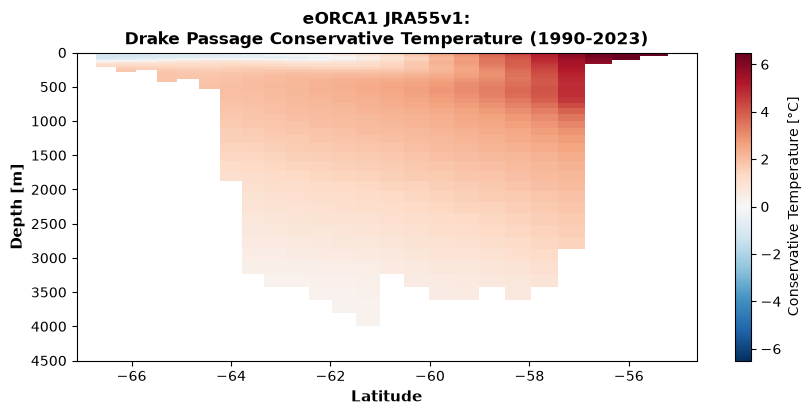

In [7]:
# -- Plot the time-mean conservative temperature along the Drake Passage section -- #
plt.figure(figsize=(10, 4))

# Plot time-mean conservative temperature across Drake Passage section:
ds_drake_passage['thetao_con'].mean(dim='time_counter').plot(x='gphib', y='depthb', yincrease=False, cbar_kwargs={"label": "Conservative Temperature [°C]"})

# Axes labels:
plt.title("eORCA1 JRA55v1:\nDrake Passage Conservative Temperature (1990-2023)", fontdict={'size':12, 'weight':'bold'})
plt.xlabel("Latitude", fontdict={'size':11, 'weight':'bold'})
plt.ylabel("Depth [m]", fontdict={'size':11, 'weight':'bold'})
plt.ylim([4500, 0])

### **Calculating Volume Transports through the Drake Passage section**

**Now, let's calculate the total zonal volume transport through our Drake Passage section.**

Since our section is defined along the U-points located at the fixed index $i^{*}$, the total volume transport is given by:

$$U(t) = \sum_{j} \sum_{k} e_{2b}(i^{*},\, j)\ e_{3b}(i^{*},\, j,\, k,\, t)\ u(i^{*},\, j,\, k,\, t)$$

where $U(t)$ is the total volume transport through the section, $u$ is the velocity component in the direction of increasing $i$, and $e_{2b}$ and $e_{3b}$ are the meridional and (time-varying) vertical grid scale factors at U-points, respectively.

Transports are positive in the direction of increasing $i$, which is approximately eastward at Drake Passage.

**We will first define the zonal volume transport through each grid cell face as a new variable `uto`:**

In [8]:
# Define grid cell face area variables (m2):
ds_drake_passage['areacello'] = ds_drake_passage['e3b'] * ds_drake_passage['e2b']
ds_drake_passage['areacello'].name = 'areacello'

# Calculate volume transport = seawater velocity x grid cell face area [m3/s]:
ds_drake_passage['uto'] = ds_drake_passage['uo'] * ds_drake_passage['areacello']
ds_drake_passage['uto'].name

ds_drake_passage

<xarray.Dataset> Size: 1MB
Dimensions:               (k: 75, axis_nbounds: 2, time_counter: 14, bdy: 26)
Coordinates:
  * k                     (k) int64 600B 1 2 3 4 5 6 7 ... 69 70 71 72 73 74 75
  * depthb                (k) float64 600B 0.5058 1.556 ... 5.698e+03 5.902e+03
  * time_counter          (time_counter) datetime64[ns] 112B 2010-07-02T12:00...
    time_centered         (time_counter) datetime64[ns] 112B dask.array<chunksize=(1,), meta=np.ndarray>
  * j                     (bdy) int64 208B 81 82 83 84 85 ... 103 104 105 106
    gphib                 (bdy) float64 208B dask.array<chunksize=(26,), meta=np.ndarray>
    glamb                 (bdy) float64 208B dask.array<chunksize=(26,), meta=np.ndarray>
    i                     float64 8B 220.5
Dimensions without coordinates: axis_nbounds, bdy
Data variables: (12/24)
    depthu_bounds         (k, axis_nbounds) float32 600B dask.array<chunksize=(25, 2), meta=np.ndarray>
    e3b                   (time_counter, k, bdy) float32 109kB dask.array<chunksize=(1, 25, 26), meta=np.ndarray>
    hfx                   (time_counter, bdy) float32 1kB dask.array<chunksize=(1, 26), meta=np.ndarray>
    hfx_adv               (time_counter, bdy) float32 1kB dask.array<chunksize=(1, 26), meta=np.ndarray>
    hfx_diff              (time_counter, bdy) float32 1kB dask.array<chunksize=(1, 26), meta=np.ndarray>
    sozosatr              (time_counter, bdy) float32 1kB dask.array<chunksize=(1, 26), meta=np.ndarray>
    ...                    ...
    thetao_con            (time_counter, k, bdy) float64 218kB dask.array<chunksize=(1, 25, 26), meta=np.ndarray>
    so_abs                (time_counter, k, bdy) float64 218kB dask.array<chunksize=(1, 25, 26), meta=np.ndarray>
    i_bdy                 (bdy) float64 208B 220.5 220.5 220.5 ... 220.5 220.5
    j_bdy                 (bdy) int64 208B 81 82 83 84 85 ... 103 104 105 106
    areacello             (time_counter, k, bdy) float64 218kB dask.array<chunksize=(1, 25, 26), meta=np.ndarray>
    uto                   (time_counter, k, bdy) float64 218kB dask.array<chunksize=(1, 25, 26), meta=np.ndarray>
Attributes:
    name:         OUTPUT/eORCA1_1y_grid_U
    description:  ocean U grid variables
    title:        ocean U grid variables
    Conventions:  CF-1.6
    timeStamp:    2024-Dec-09 10:18:04 GMT
    uuid:         8156ec68-1106-4f56-9f8c-d8798e1bd32f

### **Visualising the total volume transport through Drake Passage**

**Let's plot the time series of the total Drake Passage volume transport by summing the zonal transport `uto` over its `bdy` and `k` dimensions:**

Text(0, 0.5, 'Total Transport [Sv]')

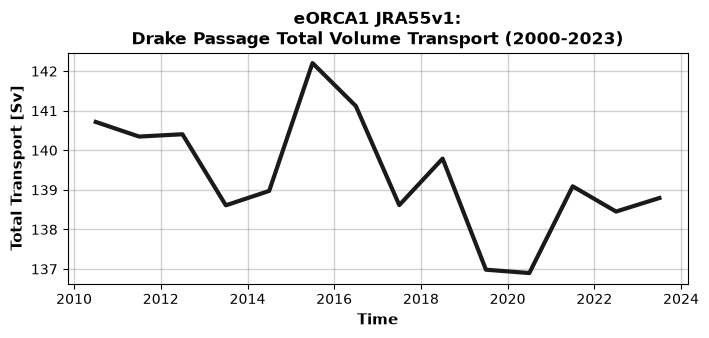

In [9]:
# -- Plot total volume transport through Drake Passage -- #
plt.figure(figsize=(8, 3))
plt.grid(visible=True, lw=1, color='0.1', alpha=0.2)

# Plot time series of total zonal volume transport:
(1E-6 * ds_drake_passage['uto'].sum(dim=["bdy", "k"])).plot(lw=3, color='0.1')

# Axes labels:
plt.title("eORCA1 JRA55v1:\nDrake Passage Total Volume Transport (2000-2023)", fontdict={'size':12, 'weight':'bold'})
plt.xlabel("Time", fontdict={'size':11, 'weight':'bold'})
plt.ylabel("Total Transport [Sv]", fontdict={'size':11, 'weight':'bold'})

### **Decomposing the total volume transport through Drake Passage**

**Next, we will decompose the total volume transport through Drake Passage into a barotropic and baroclinic contribution following the definition used in observations.**

Defining $k_{b}(j)$ as the k-index of the bottommost wet U-point at $(i^{*},\, j)$, the barotropic and baroclinic velocities are:

$$u_{\mathrm{bt}}(i^{*},\, j,\, k,\, t) = u(i^{*},\, j,\, k_{b}(j),\, t) \qquad u_{\mathrm{bc}} = u - u_{\mathrm{bt}}$$

where $u_{\mathrm{bt}}$ is uniform with depth over all wet U-points in each water column. The corresponding volume transports are:

* Barotropic transport $U_{\mathrm{bt}}(t)$:

$$U_{\mathrm{bt}}(t) = \sum_{j} \sum_{k} e_{2b}\ e_{3b}\ u_{\mathrm{bt}} = \sum_{j} e_{2b}\ H_{u}(t)\ u(i^{*},\, j,\, k_{b}(j),\, t)$$

* Baroclinic transport $U_{\mathrm{bc}}(t)$:

$$U_{\mathrm{bc}}(t) = \sum_{j} \sum_{k} e_{2b}\ e_{3b}\ u_{\mathrm{bc}} = U(t) - U_{\mathrm{bt}}(t)$$

where $H_{u}(t) = \sum_{k} e_{3b}$ is the ocean depth at U-points (i.e., the masked sum of the vertical scale factors).

In [10]:
# Identify bottommost wet grid cell indices:
k_bottom = ds_drake_passage['bmask'].argmin(dim="k").load() - 1

# Calculate barotropic component of the zonal velocity:
ds_drake_passage["uo_bt"] = (
    ds_drake_passage["uo"]
    .isel(k=k_bottom)
    .broadcast_like(ds_drake_passage['uo'])
    .where(ds_drake_passage['bmask'])
    )
ds_drake_passage["uo_bt"].name = "uo_bt"

# Calculate residual baroclinic component of the zonal velocity:
ds_drake_passage["uo_bc"] = ds_drake_passage['uo'] - ds_drake_passage["uo_bt"]
ds_drake_passage["uo_bc"].name = "uo_bc"

In [11]:
# Calculate total, barotropic, and baroclinic volume transport through the Drake Passage:
ds_drake_passage["Uo"] = 1E-6 * (ds_drake_passage["uo"] * ds_drake_passage['areacello']).sum(dim=["bdy", "k"]).compute()
ds_drake_passage["Uo_bt"] = 1E-6 * (ds_drake_passage["uo_bt"] * ds_drake_passage['areacello']).sum(dim=["bdy", "k"]).compute()
ds_drake_passage["Uo_bc"] = 1E-6 * (ds_drake_passage["uo_bc"] * ds_drake_passage['areacello']).sum(dim=["bdy", "k"]).compute()

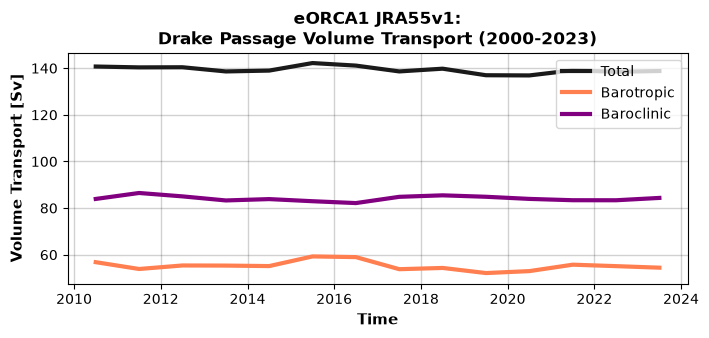

In [12]:
# -- Plot volume transport components through Drake Passage -- #
plt.figure(figsize=(8, 3))
plt.grid(visible=True, lw=1, color='0.1', alpha=0.2)

# Plot time series of volume transport component anomalies:
ds_drake_passage["Uo"].plot(lw=3, color='0.1', label='Total')
ds_drake_passage["Uo_bt"].plot(lw=3, color='coral', label='Barotropic')
ds_drake_passage["Uo_bc"].plot(lw=3, color='purple', label='Baroclinic')

# Axes labels and legend:
plt.title("eORCA1 JRA55v1:\nDrake Passage Volume Transport (2000-2023)", fontdict={'size':12, 'weight':'bold'})
plt.xlabel("Time", fontdict={'size':11, 'weight':'bold'})
plt.ylabel("Volume Transport [Sv]", fontdict={'size':11, 'weight':'bold'})
plt.legend(loc="upper right")